# Penguin Species Classification Using Support Vector Machine

**Course:** AMDS3002 / CSCI4221 – Machine Learning  
**Objective:** Build an SVM model that predicts whether a penguin is an Adelie, Chinstrap, or Gentoo using its physical measurements.  
**Dataset:** Palmer Penguins (Kaggle) – 344 penguins, 3 species.

## Setup

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)

RANDOM_STATE = 42

## Task 1 – Load the dataset

In [18]:
df = pd.read_csv('../data/penguins_size.csv')
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [19]:
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (344, 7)


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


In [21]:
df.isnull().sum().to_frame('missing_values')

,missing_values
species,0
island,0
culmen_length_mm,2
culmen_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,10


In [22]:
print("Rows with at least one missing value:", df.isnull().any(axis=1).sum())
print("\nClass distribution:")
print(df['species'].value_counts())

Rows with at least one missing value: 10

Class distribution:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


**Task 1 findings**

- 344 rows and 7 columns, matching the project description.
- Class counts: Adelie 152, Gentoo 124, Chinstrap 68.
- Two penguins have no measurements at all, and `sex` is missing for 10 penguins. The two empty rows are among those 10, so only **10 rows** contain any missing value (`dropna()` leaves 334 rows).

## Task 2 – Remove missing records and select features

1. Remove missing records

In [23]:
print("Shape before dropna():", df.shape)
df_clean = df.dropna()
print("Shape after dropna(): ", df_clean.shape)
print("Missing values left:  ", df_clean.isnull().sum().sum())
print("\nClass distribution after cleaning:")
print(df_clean['species'].value_counts())

Shape before dropna(): (344, 7)
Shape after dropna():  (334, 7)
Missing values left:   0

Class distribution after cleaning:
species
Adelie       146
Gentoo       120
Chinstrap     68
Name: count, dtype: int64


2. Select features and Target

In [24]:
features = ['culmen_length_mm', 'culmen_depth_mm']

X = df_clean[features]
y = df_clean['species']

print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()

X shape: (334, 2)
y shape: (334,)


,culmen_length_mm,culmen_depth_mm
0,39.1,18.7
1,39.5,17.4
2,40.3,18.0
4,36.7,19.3
5,39.3,20.6


## Task 2 – Remove missing records and select features

**Findings**

- `dropna()` removed 10 rows, leaving **334 penguins** with no missing values.
- Class counts after cleaning: Adelie 146, Gentoo 120, Chinstrap 68. Adelie and Gentoo each lost a few penguins, and Chinstrap was unaffected.
- **Selected features:** culmen length (mm) and culmen depth (mm). **Target:** `species`.
- I chose these two because they are the measurements that separate the three species best in 2D, and two features also allow plotting the decision boundary in Task 7.

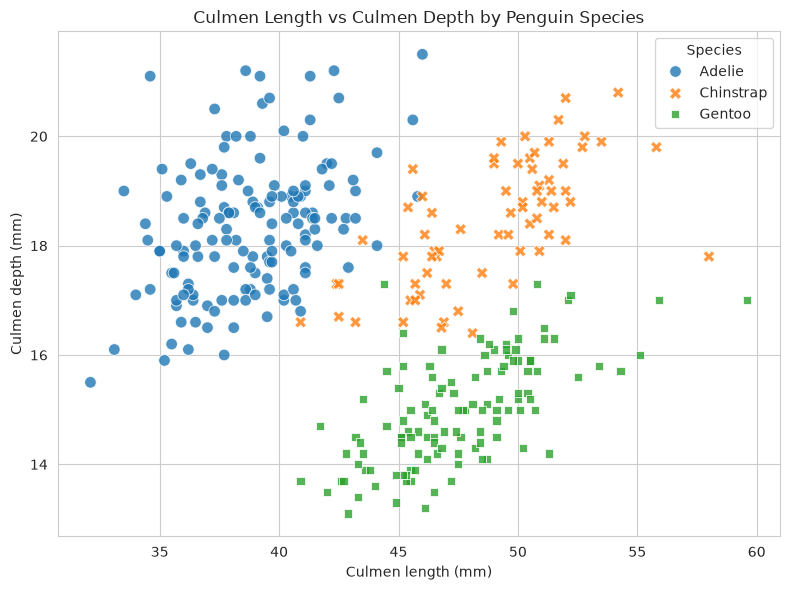

In [25]:
sns.set_style('whitegrid')

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_clean,
    x='culmen_length_mm',
    y='culmen_depth_mm',
    hue='species',
    style='species',
    s=70,
    alpha=0.8
)
plt.title('Culmen Length vs Culmen Depth by Penguin Species')
plt.xlabel('Culmen length (mm)')
plt.ylabel('Culmen depth (mm)')
plt.legend(title='Species')
plt.tight_layout()
plt.savefig('../images/scatter_plot.png', dpi=150)
plt.show()

## Task 3 – Scatter plot

**Observations**

1. **Gentoo forms a well-separated group.** Gentoo penguins sit at the bottom of the plot (culmen depth about 13–17 mm), while Adelie and Chinstrap are mostly above 16 mm. Culmen depth alone almost separates Gentoo from the other two.
2. **Adelie and Chinstrap are separated mainly by culmen length, not depth.** Their average depths are nearly the same (about 18.3 and 18.4 mm), but Adelie bills are shorter (average about 38.8 mm) and Chinstrap bills are longer (average about 48.8 mm). Some points overlap in the 41–46 mm length range.

80/20 split

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set: ", X_test.shape)
print("\nTraining class counts:\n", y_train.value_counts())
print("\nTesting class counts:\n", y_test.value_counts())

Training set: (267, 2)
Testing set:  (67, 2)

Training class counts:
 species
Adelie       117
Gentoo        96
Chinstrap     54
Name: count, dtype: int64

Testing class counts:
 species
Adelie       29
Gentoo       24
Chinstrap    14
Name: count, dtype: int64


In [27]:
scaler = StandardScaler()

# Learn mean/std from the TRAINING data only, then apply to both sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training mean after scaling:", X_train_scaled.mean(axis=0).round(3))
print("Training std after scaling: ", X_train_scaled.std(axis=0).round(3))

Training mean after scaling: [0. 0.]
Training std after scaling:  [1. 1.]


## Task 4 – Train/test split and feature scaling

- The data was split **80% training / 20% testing** (267 / 67 penguins) with `random_state=42` so results are reproducible.
- `stratify=y` keeps the species proportions the same in both sets, which matters because Chinstrap is the smallest class.
- `StandardScaler` was **fitted on the training set only** and then applied to the test set. This avoids data leakage, since the test set must stay unseen until evaluation.